<a href="https://colab.research.google.com/github/Sunidhipatilcodes/THE-ML-ACTIVITY-/blob/main/Activity1_Dataset_Preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Activity 1: Dataset Preparation
**Course:** Machine Learning
 T.Y. B.Tech (AI & DS)




## Step 1: Select a dataset

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

URL = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"
LOCAL = "penguins.csv"   # fallback if you downloaded the file manually

def load_data():
    if os.path.exists(LOCAL):
        return pd.read_csv(LOCAL), "local file"
    try:
        return pd.read_csv(URL), "GitHub raw URL"
    except Exception as e:
        print("URL failed, trying seaborn copy:", e)
        return sns.load_dataset("penguins"), "seaborn built-in copy"

df_raw, loaded_from = load_data()
print("Loaded from:", loaded_from)
print("Rows:", df_raw.shape[0], "| Columns:", df_raw.shape[1])

Loaded from: GitHub raw URL
Rows: 344 | Columns: 8


## Step 2: Load and inspect the dataset

In [3]:
print("First 5 rows"); display(df_raw.head())
print("Last 5 rows");  display(df_raw.tail())

First 5 rows


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


Last 5 rows


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


In [4]:
print("Shape (rows, columns):", df_raw.shape)
print("\nColumn names:", list(df_raw.columns))
print("\nData types:"); print(df_raw.dtypes)
df_raw.info()

Shape (rows, columns): (344, 8)

Column names: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']

Data types:
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dt

## Step 3: Data types and basic statistics

In [5]:
num_cols = df_raw.select_dtypes(include="number").columns.tolist()
cat_cols = df_raw.select_dtypes(exclude="number").columns.tolist()
print("Numerical columns :", num_cols)
print("Categorical columns:", cat_cols)
display(df_raw[num_cols].describe().T)

Numerical columns : ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'year']
Categorical columns: ['species', 'island', 'sex']


,count,mean,std,min,25%,50%,75%,max
bill_length_mm,342.0,43.921930,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,17.151170,1.974793,13.1,15.600,17.30,18.7,21.5
flipper_length_mm,342.0,200.915205,14.061714,172.0,190.000,197.00,213.0,231.0
body_mass_g,342.0,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.0,6300.0
year,344.0,2008.029070,0.818356,2007.0,2007.000,2008.00,2009.0,2009.0


In [6]:
# Suspicious values / formats: look at the raw category labels and the numeric ranges
for c in cat_cols:
    print(c, "->", df_raw[c].unique())

species -> ['Adelie' 'Gentoo' 'Chinstrap']
island -> ['Torgersen' 'Biscoe' 'Dream']
sex -> ['male' 'female' nan]


## Step 4: Identify missing values

In [7]:
missing = pd.DataFrame({
    "missing_count": df_raw.isnull().sum(),
    "missing_percent": (df_raw.isnull().mean() * 100).round(2)
})
display(missing.sort_values("missing_count", ascending=False))
print("Columns with no missing values:", missing.index[missing.missing_count == 0].tolist())
print("Columns needing attention     :", missing.index[missing.missing_count > 0].tolist())

,missing_count,missing_percent
sex,11,3.20
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
bill_length_mm,2,0.58
body_mass_g,2,0.58
island,0,0.00
species,0,0.00
year,0,0.00


Columns with no missing values: ['species', 'island', 'year']
Columns needing attention     : ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


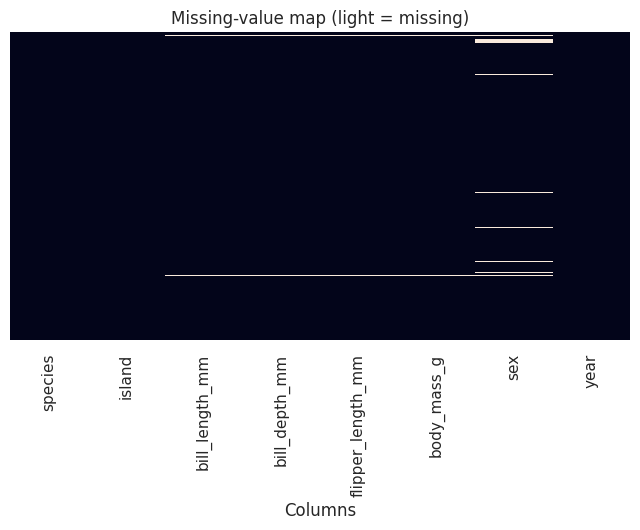

In [8]:
plt.figure(figsize=(8, 4))
sns.heatmap(df_raw.isnull(), cbar=False, yticklabels=False)
plt.title("Missing-value map (light = missing)")
plt.xlabel("Columns")
plt.show()

## Step 5: Handle missing values


In [9]:
df = df_raw.copy()          # keep the original untouched

# Rows with no measurement at all are useless
measure_cols = [c for c in num_cols if c != "year"]
empty_rows = df[measure_cols].isnull().all(axis=1)
print("Rows with all measurements missing:", int(empty_rows.sum()))
df = df[~empty_rows].copy()

for c in num_cols:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].median())
for c in cat_cols:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].mode()[0])

print("\nMissing values after cleaning:")
print(df.isnull().sum())
print("Shape after cleaning:", df.shape)

Rows with all measurements missing: 2

Missing values after cleaning:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
year                 0
dtype: int64
Shape after cleaning: (342, 8)


## Step 6: Duplicates and consistency

In [10]:
dups = df.duplicated()
print("Duplicate rows:", int(dups.sum()))
display(df[dups])

Duplicate rows: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year


In [11]:
# Clean category labels: strip spaces and unify capitalisation
for c in cat_cols:
    df[c] = df[c].astype(str).str.strip().str.title()
for c in cat_cols:
    print(c, "->", df[c].unique())

# Remove only true unwanted copies (none expected, but the code is safe)
before = len(df)
df = df.drop_duplicates()
print("Rows removed as duplicates:", before - len(df))

species -> ['Adelie' 'Gentoo' 'Chinstrap']
island -> ['Torgersen' 'Biscoe' 'Dream']
sex -> ['Male' 'Female']
Rows removed as duplicates: 0


## Step 7: Basic EDA

In [12]:
display(df[measure_cols].describe().T)
print("\nFrequency counts - species"); print(df["species"].value_counts())
print("\nFrequency counts - island");  print(df["island"].value_counts())
print("\nFrequency counts - sex");     print(df["sex"].value_counts())

,count,mean,std,min,25%,50%,75%,max
bill_length_mm,342.0,43.921930,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,17.151170,1.974793,13.1,15.600,17.30,18.7,21.5
flipper_length_mm,342.0,200.915205,14.061714,172.0,190.000,197.00,213.0,231.0
body_mass_g,342.0,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.0,6300.0



Frequency counts - species
species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64

Frequency counts - island
island
Biscoe       167
Dream        124
Torgersen     51
Name: count, dtype: int64

Frequency counts - sex
sex
Male      177
Female    165
Name: count, dtype: int64


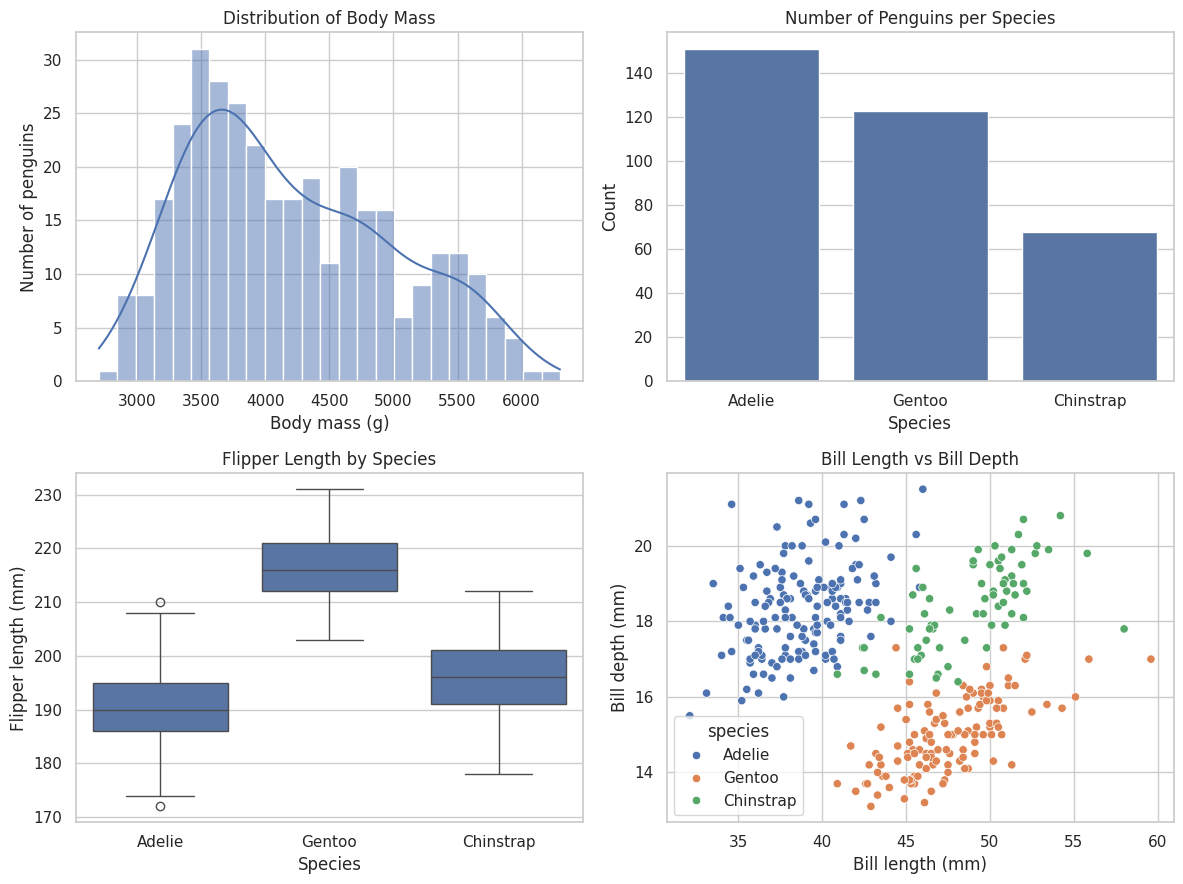

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.histplot(df["body_mass_g"], bins=25, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Distribution of Body Mass")
axes[0, 0].set_xlabel("Body mass (g)"); axes[0, 0].set_ylabel("Number of penguins")

sns.countplot(data=df, x="species", ax=axes[0, 1])
axes[0, 1].set_title("Number of Penguins per Species")
axes[0, 1].set_xlabel("Species"); axes[0, 1].set_ylabel("Count")

sns.boxplot(data=df, x="species", y="flipper_length_mm", ax=axes[1, 0])
axes[1, 0].set_title("Flipper Length by Species")
axes[1, 0].set_xlabel("Species"); axes[1, 0].set_ylabel("Flipper length (mm)")

sns.scatterplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species", ax=axes[1, 1])
axes[1, 1].set_title("Bill Length vs Bill Depth")
axes[1, 1].set_xlabel("Bill length (mm)"); axes[1, 1].set_ylabel("Bill depth (mm)")

plt.tight_layout(); plt.show()

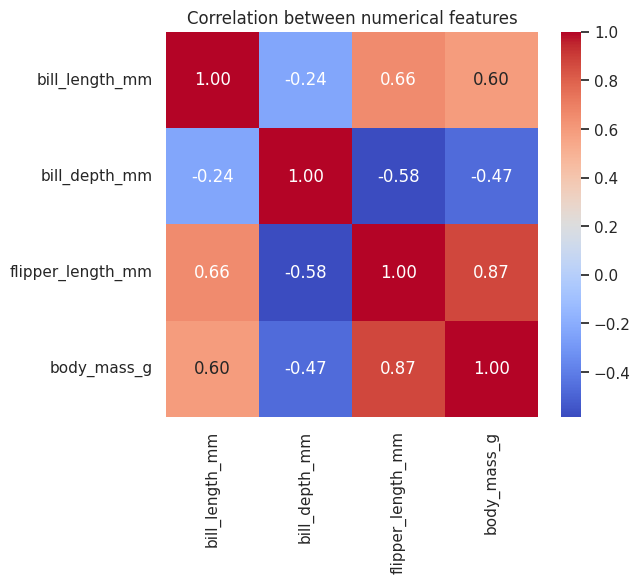

In [14]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[measure_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between numerical features")
plt.show()

## Step 8: Encode categorical features

In [15]:
print("BEFORE encoding (sample):")
display(df[["island", "sex"]].head())

df_enc = pd.get_dummies(df, columns=["island", "sex"], dtype=int)

print("AFTER encoding (sample):")
display(df_enc.filter(regex="^(island|sex)_").head())
print("New shape:", df_enc.shape)

BEFORE encoding (sample):


,island,sex
0,Torgersen,Male
1,Torgersen,Female
2,Torgersen,Female
4,Torgersen,Female
5,Torgersen,Male


AFTER encoding (sample):


,island_Biscoe,island_Dream,island_Torgersen,sex_Female,sex_Male
0,0,0,1,0,1
1,0,0,1,1,0
2,0,0,1,1,0
4,0,0,1,1,0
5,0,0,1,0,1


New shape: (342, 11)


## Step 9: Scale numerical features


In [16]:
scale_cols = measure_cols            # numeric measurement columns only
train_idx, test_idx = train_test_split(
    df_enc.index, test_size=0.2, random_state=42, stratify=df_enc["species"])

scaler = StandardScaler()
df_final = df_enc.copy()
df_final[scale_cols] = df_final[scale_cols].astype(float)
df_final.loc[train_idx, scale_cols] = scaler.fit_transform(df_enc.loc[train_idx, scale_cols])
df_final.loc[test_idx,  scale_cols] = scaler.transform(df_enc.loc[test_idx,  scale_cols])
df_final["split"] = "train"
df_final.loc[test_idx, "split"] = "test"

print("Scaling parameters learned from training data only")
print(pd.DataFrame({"mean": scaler.mean_, "std": scaler.scale_}, index=scale_cols).round(3))
print("\nTrain rows:", len(train_idx), "| Test rows:", len(test_idx))
print("\nMean/std of scaled TRAIN columns (should be ~0 and ~1):")
display(df_final.loc[train_idx, scale_cols].agg(["mean", "std"]).round(3))

Scaling parameters learned from training data only
                       mean      std
bill_length_mm       44.072    5.486
bill_depth_mm        17.135    2.005
flipper_length_mm   200.949   13.882
body_mass_g        4209.799  798.618

Train rows: 273 | Test rows: 69

Mean/std of scaled TRAIN columns (should be ~0 and ~1):


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
mean,0.000,0.000,-0.000,-0.000
std,1.002,1.002,1.002,1.002


## Step 10: Save the prepared dataset

In [17]:
print("Final shape:", df_final.shape)
print("Remaining missing values:", int(df_final.isnull().sum().sum()))
print("Remaining duplicate rows:", int(df_final.duplicated().sum()))

OUT = "penguins_prepared.csv"
df_final.to_csv(OUT, index=False)
print("Saved as:", OUT)
display(df_final.head())

Final shape: (342, 12)
Remaining missing values: 0
Remaining duplicate rows: 0
Saved as: penguins_prepared.csv


,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year,island_Biscoe,island_Dream,island_Torgersen,sex_Female,sex_Male,split
0,Adelie,-0.906258,0.780723,-1.436973,-0.575743,2007,0,0,1,0,1,train
1,Adelie,-0.833346,0.132283,-1.076806,-0.513135,2007,0,0,1,1,0,test
2,Adelie,-0.687522,0.431563,-0.428506,-1.201824,2007,0,0,1,1,0,train
4,Adelie,-1.343730,1.080003,-0.572573,-0.951392,2007,0,0,1,1,0,train
5,Adelie,-0.869802,1.728443,-0.788673,-0.700959,2007,0,0,1,0,1,train


In [18]:
df_raw.to_csv("penguins_raw.csv", index=False)
print("saved", df_raw.shape)

saved (344, 8)
